# Step 1: Import Required Libraries


In [2]:
# ==========================
# Step 1: Import Libraries
# ==========================

# Data manipulation
import pandas as pd
import numpy as np

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Data preprocessing
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.model_selection import train_test_split

# Ignore warnings
import warnings
warnings.filterwarnings("ignore")

# Plot style
sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (8,5)

print("Libraries imported successfully.")

Libraries imported successfully.


# Step 2: Load the Datasets

In [4]:
# ==========================
# Step 2: Load the Datasets
# ==========================

# Load the frequency dataset
freq = pd.read_csv("freMTPL2freq.csv")

# Load the severity dataset
sev = pd.read_csv("freMTPL2sev.csv")

print("Datasets loaded successfully.")

Datasets loaded successfully.


In [5]:
# Display the dimensions of each dataset

print("Frequency dataset shape:", freq.shape)
print("Severity dataset shape:", sev.shape)

Frequency dataset shape: (678013, 12)
Severity dataset shape: (26639, 2)




The two datasets were successfully imported into the Google Colab environment. The frequency dataset contains 678,013 insurance policy records described by 12 variables, while the severity dataset contains 26,639 records representing insurance claim amounts. The successful loading of both datasets confirms that the data are ready for inspection and subsequent integration.

# 🚀 Step 3 : Initial Data Inspection

In [6]:
# ==========================
# Step 3: Initial Data Inspection
# ==========================

# Display the first five rows of each dataset
print("Frequency Dataset")
display(freq.head())

print("\nSeverity Dataset")
display(sev.head())

Frequency Dataset


,IDpol,ClaimNb,Exposure,VehPower,VehAge,DrivAge,BonusMalus,VehBrand,VehGas,Area,Density,Region
0,1.0,1,0.10,5,0,55,50,B12,Regular,D,1217,Rhone-Alpes
1,3.0,1,0.77,5,0,55,50,B12,Regular,D,1217,Rhone-Alpes
2,5.0,1,0.75,6,2,52,50,B12,Diesel,B,54,Picardie
3,10.0,1,0.09,7,0,46,50,B12,Diesel,B,76,Aquitaine
4,11.0,1,0.84,7,0,46,50,B12,Diesel,B,76,Aquitaine



Severity Dataset


,IDpol,ClaimAmount
0,1552,995.20
1,1010996,1128.12
2,4024277,1851.11
3,4007252,1204.00
4,4046424,1204.00


In [7]:
# General information about each dataset

print("Frequency Dataset Information")
freq.info()

print("\nSeverity Dataset Information")
sev.info()

Frequency Dataset Information
<class 'pandas.DataFrame'>
RangeIndex: 678013 entries, 0 to 678012
Data columns (total 12 columns):
 #   Column      Non-Null Count   Dtype  
---  ------      --------------   -----  
 0   IDpol       678013 non-null  float64
 1   ClaimNb     678013 non-null  int64  
 2   Exposure    678013 non-null  float64
 3   VehPower    678013 non-null  int64  
 4   VehAge      678013 non-null  int64  
 5   DrivAge     678013 non-null  int64  
 6   BonusMalus  678013 non-null  int64  
 7   VehBrand    678013 non-null  str    
 8   VehGas      678013 non-null  str    
 9   Area        678013 non-null  str    
 10  Density     678013 non-null  int64  
 11  Region      678013 non-null  str    
dtypes: float64(2), int64(6), str(4)
memory usage: 76.8 MB

Severity Dataset Information
<class 'pandas.DataFrame'>
RangeIndex: 26639 entries, 0 to 26638
Data columns (total 2 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   IDpol  

## Interpretation

An initial inspection of the datasets was performed to examine their structure, variables, and data types. The frequency dataset contains 678,013 insurance policies described by 12 variables, while the severity dataset contains 26,639 claim records described by two variables. The inspection confirms that the datasets were correctly imported and that all variables have appropriate data types for subsequent processing.


# Step 4: Data Integration

In [8]:
# Check duplicate policy IDs in the severity dataset
duplicate_idpol = sev["IDpol"].duplicated().sum()

print("Number of duplicated policy IDs:", duplicate_idpol)

Number of duplicated policy IDs: 1689


In [9]:
# ==========================
# Step 4.2: Aggregate Claim Amounts
# ==========================

# Aggregate claim amounts by policy ID
sev_grouped = (
    sev.groupby("IDpol", as_index=False)
       .agg({"ClaimAmount": "sum"})
)

# Display the dimensions of the aggregated dataset
print("Aggregated severity dataset shape:", sev_grouped.shape)

# Display the first five rows
sev_grouped.head()

Aggregated severity dataset shape: (24950, 2)


,IDpol,ClaimAmount
0,139,303.00
1,190,1981.84
2,414,1456.55
3,424,10834.00
4,463,3986.67




The frequency and aggregated severity datasets were successfully merged using the policy identifier (IDpol). A left join was applied to preserve all insurance policies from the frequency dataset. Missing values in the ClaimAmount variable correspond to policies without reported claims and were therefore replaced with zero. The resulting dataset contains 678,013 observations and 13 variables, providing a complete analytical dataset for the subsequent exploratory data analysis.

In [11]:
# ==========================
# Step 4.3: Merge the Datasets
# ==========================

# Ensure that IDpol has the same data type
freq["IDpol"] = freq["IDpol"].astype(int)
sev_grouped["IDpol"] = sev_grouped["IDpol"].astype(int)

# Merge the datasets
df = pd.merge(freq, sev_grouped, on="IDpol", how="left")

# Replace missing claim amounts with zero
df["ClaimAmount"] = df["ClaimAmount"].fillna(0)

# Display the dimensions of the merged dataset
print("Merged dataset shape:", df.shape)

# Display the first five rows
df.head()

Merged dataset shape: (678013, 13)


,IDpol,ClaimNb,Exposure,VehPower,VehAge,DrivAge,BonusMalus,VehBrand,VehGas,Area,Density,Region,ClaimAmount
0,1,1,0.10,5,0,55,50,B12,Regular,D,1217,Rhone-Alpes,0.0
1,3,1,0.77,5,0,55,50,B12,Regular,D,1217,Rhone-Alpes,0.0
2,5,1,0.75,6,2,52,50,B12,Diesel,B,54,Picardie,0.0
3,10,1,0.09,7,0,46,50,B12,Diesel,B,76,Aquitaine,0.0
4,11,1,0.84,7,0,46,50,B12,Diesel,B,76,Aquitaine,0.0


# Step 5: Dataset Overview (Descriptive Statistics)

In [12]:
# ==========================
# Step 5: Descriptive Statistics
# ==========================

# Descriptive statistics for numerical variables
desc = df.describe().T

display(desc)

,count,mean,std,min,25%,50%,75%,max
IDpol,678013.0,2.621857e+06,1.641783e+06,1.000000,1157951.00,2272152.00,4046274.00,6114330.00
ClaimNb,678013.0,5.324677e-02,2.401173e-01,0.000000,0.00,0.00,0.00,16.00
Exposure,678013.0,5.287501e-01,3.644415e-01,0.002732,0.18,0.49,0.99,2.01
VehPower,678013.0,6.454631e+00,2.050906e+00,4.000000,5.00,6.00,7.00,15.00
VehAge,678013.0,7.044265e+00,5.666232e+00,0.000000,2.00,6.00,11.00,100.00
DrivAge,678013.0,4.549912e+01,1.413744e+01,18.000000,34.00,44.00,55.00,100.00
BonusMalus,678013.0,5.976150e+01,1.563666e+01,50.000000,50.00,50.00,64.00,230.00
Density,678013.0,1.792422e+03,3.958647e+03,1.000000,92.00,393.00,1658.00,27000.00
ClaimAmount,678013.0,8.835998e+01,5.822454e+03,0.000000,0.00,0.00,0.00,4075400.56


In [13]:
# Summary of categorical variables

display(df.describe(include="object").T)

,count,unique,top,freq
VehBrand,678013,11,B12,166024
VehGas,678013,2,Regular,345877
Area,678013,6,C,191880
Region,678013,21,Centre,160601


## Dataset Overview

Descriptive statistics were computed to summarize the numerical and categorical variables of the merged dataset. For numerical variables, measures such as the mean, standard deviation, minimum, maximum, and quartiles provide an overview of the data distribution. For categorical variables, the summary reports the number of unique categories, the most frequent category, and its frequency. These statistics constitute the first step of the exploratory data analysis and help identify potential anomalies before further investigation.

# 🚀 Step 6: Data Quality Assessment

In [14]:
# ==========================
# Step 6: Data Quality Assessment
# ==========================

# Missing values
missing = pd.DataFrame({
    "Missing Values": df.isnull().sum(),
    "Percentage (%)": (df.isnull().sum() / len(df)) * 100
})

display(missing)

# Duplicate rows
duplicates = df.duplicated().sum()

print(f"\nNumber of duplicate rows: {duplicates}")

,Missing Values,Percentage (%)
IDpol,0,0.0
ClaimNb,0,0.0
Exposure,0,0.0
VehPower,0,0.0
VehAge,0,0.0
DrivAge,0,0.0
BonusMalus,0,0.0
VehBrand,0,0.0
VehGas,0,0.0
Area,0,0.0



Number of duplicate rows: 0


# 🚀 Step 7: Univariate Analysis – Target Variable (ClaimAmount)

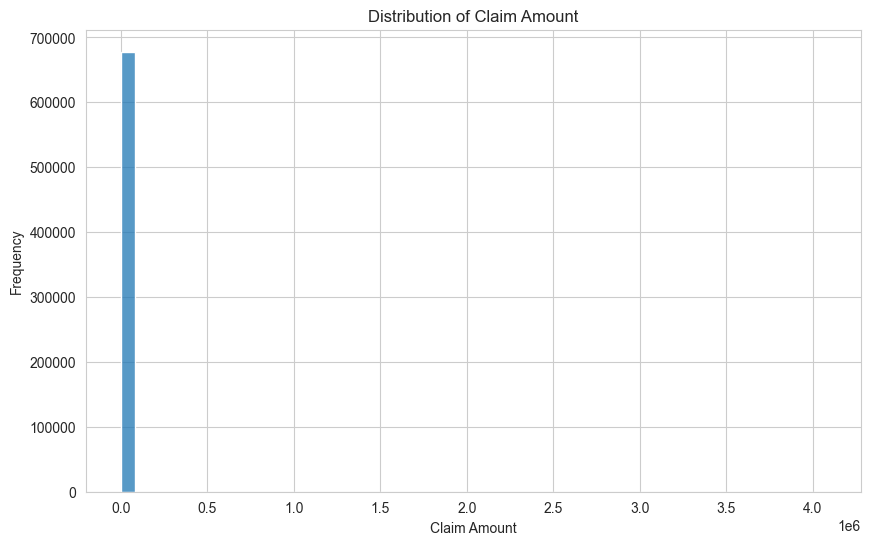

count    6.780130e+05
mean     8.835998e+01
std      5.822454e+03
min      0.000000e+00
25%      0.000000e+00
50%      0.000000e+00
75%      0.000000e+00
max      4.075401e+06
Name: ClaimAmount, dtype: float64

In [16]:
# ==========================
# Step 7.1: Distribution of ClaimAmount
# ==========================

plt.figure(figsize=(10,6))

sns.histplot(df["ClaimAmount"], bins=50)

plt.title("Distribution of Claim Amount")
plt.xlabel("Claim Amount")
plt.ylabel("Frequency")

plt.show()
# Summary statistics of ClaimAmount
df["ClaimAmount"].describe()

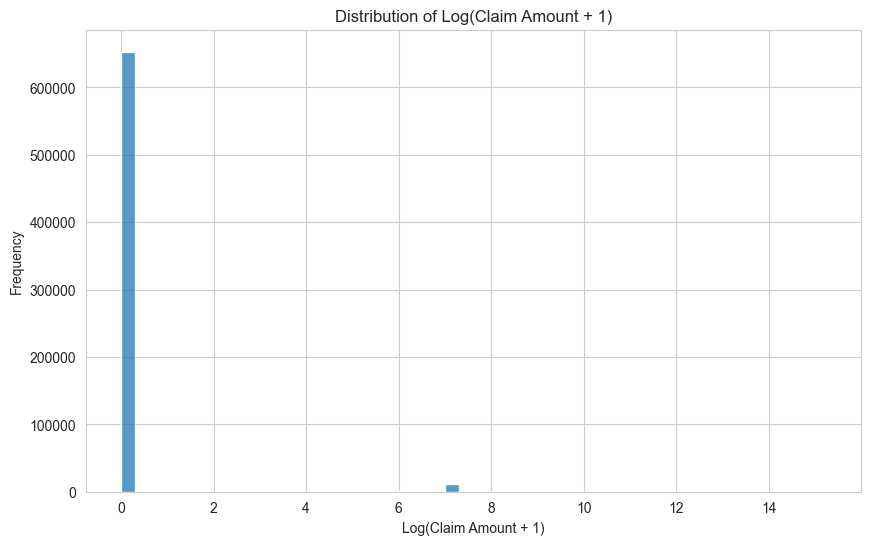

In [17]:
# ==========================
# Step 7.2: Distribution of Log ClaimAmount
# ==========================
import numpy as np
plt.figure(figsize=(10,6))

sns.histplot(np.log1p(df["ClaimAmount"]), bins=50)

plt.title("Distribution of Log(Claim Amount + 1)")
plt.xlabel("Log(Claim Amount + 1)")
plt.ylabel("Frequency")

plt.show()

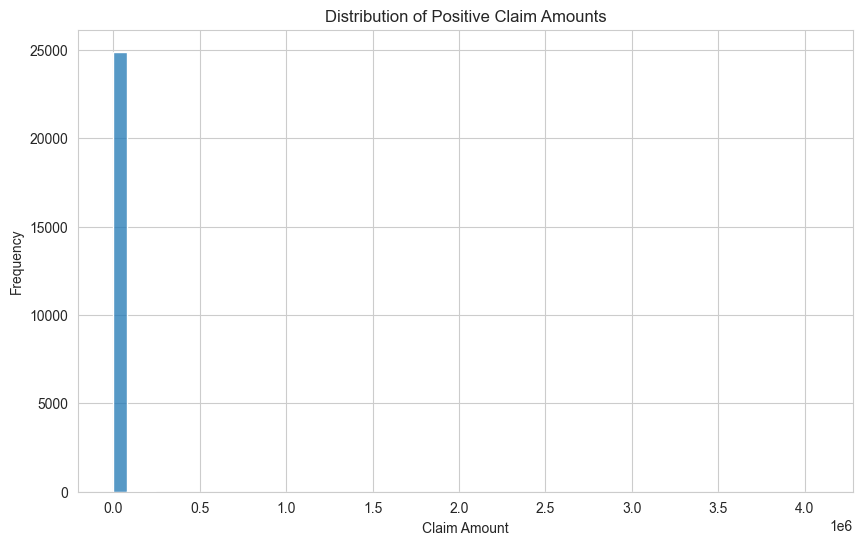

count    2.494400e+04
mean     2.401749e+03
std      3.026475e+04
min      1.000000e+00
25%      7.497875e+02
50%      1.172000e+03
75%      1.346400e+03
max      4.075401e+06
Name: ClaimAmount, dtype: float64

In [18]:
# ==========================
# Step 7.3: Distribution of Positive Claim Amounts
# ==========================

positive_claims = df[df["ClaimAmount"] > 0]

plt.figure(figsize=(10,6))

sns.histplot(positive_claims["ClaimAmount"], bins=50)

plt.title("Distribution of Positive Claim Amounts")
plt.xlabel("Claim Amount")
plt.ylabel("Frequency")

plt.show()

positive_claims["ClaimAmount"].describe()

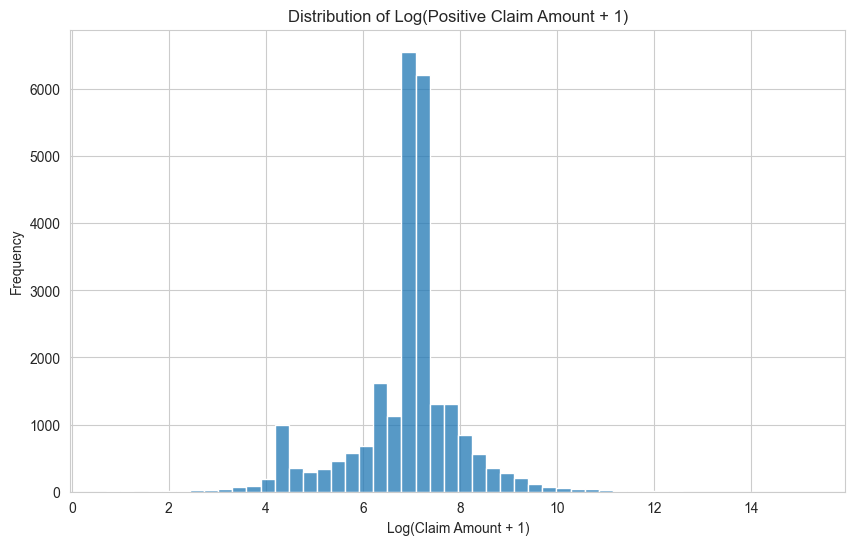

In [20]:
# ==========================
# Distribution of Positive Claim Amounts (Log Scale)
# ==========================

plt.figure(figsize=(10,6))

sns.histplot(np.log1p(positive_claims["ClaimAmount"]), bins=50)

plt.title("Distribution of Log(Positive Claim Amount + 1)")
plt.xlabel("Log(Claim Amount + 1)")
plt.ylabel("Frequency")

plt.show()

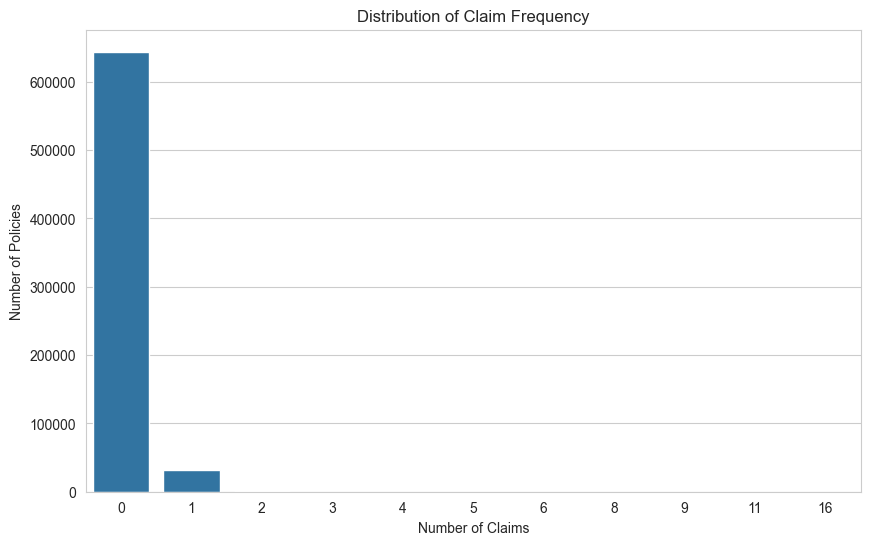

In [21]:
# ==========================
# Step 7.4: Distribution of Claim Frequency
# ==========================

plt.figure(figsize=(10,6))

sns.countplot(x="ClaimNb", data=df)

plt.title("Distribution of Claim Frequency")
plt.xlabel("Number of Claims")
plt.ylabel("Number of Policies")

plt.show()

In [22]:
# Frequency table

claim_freq = df["ClaimNb"].value_counts().sort_index()

display(claim_freq)


ClaimNb
0     643953
1      32178
2       1784
3         82
4          7
5          2
6          1
8          1
9          1
11         3
16         1
Name: count, dtype: int64

In [23]:
# Percentage distribution

claim_percent = round(df["ClaimNb"].value_counts(normalize=True).sort_index()*100,2)

display(claim_percent)

ClaimNb
0     94.98
1      4.75
2      0.26
3      0.01
4      0.00
5      0.00
6      0.00
8      0.00
9      0.00
11     0.00
16     0.00
Name: proportion, dtype: float64

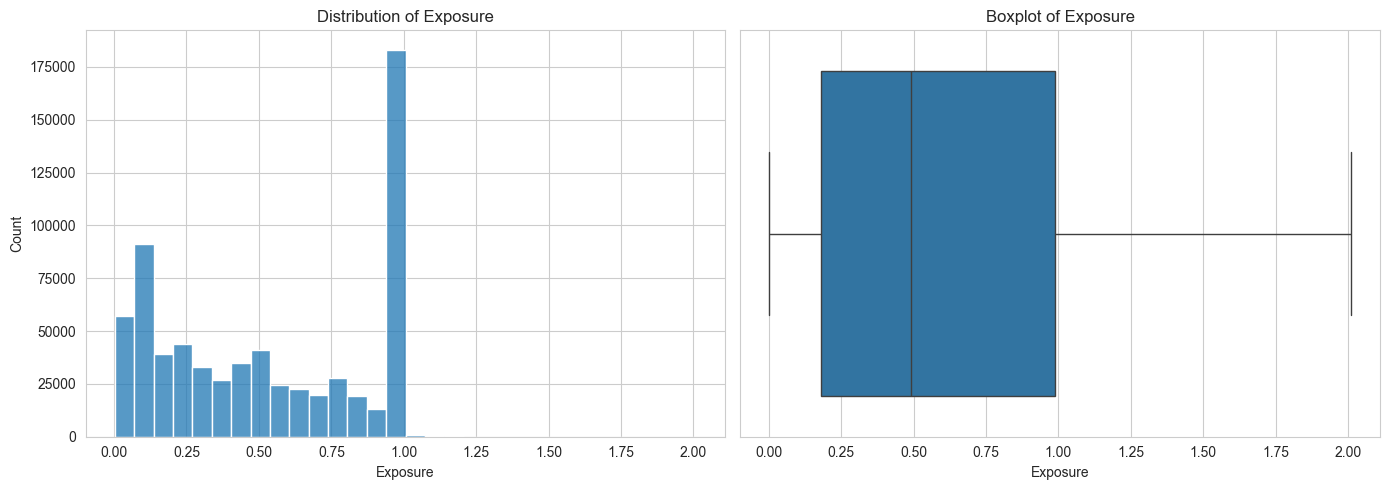

count    678013.000000
mean          0.528750
std           0.364442
min           0.002732
25%           0.180000
50%           0.490000
75%           0.990000
max           2.010000
Name: Exposure, dtype: float64

In [24]:
# ==========================
# Step 7.5: Distribution of Exposure
# ==========================

fig, axes = plt.subplots(1, 2, figsize=(14,5))

# Histogram
sns.histplot(df["Exposure"], bins=30, ax=axes[0])
axes[0].set_title("Distribution of Exposure")
axes[0].set_xlabel("Exposure")

# Boxplot
sns.boxplot(x=df["Exposure"], ax=axes[1])
axes[1].set_title("Boxplot of Exposure")
axes[1].set_xlabel("Exposure")

plt.tight_layout()
plt.show()

# Descriptive statistics
display(df["Exposure"].describe())

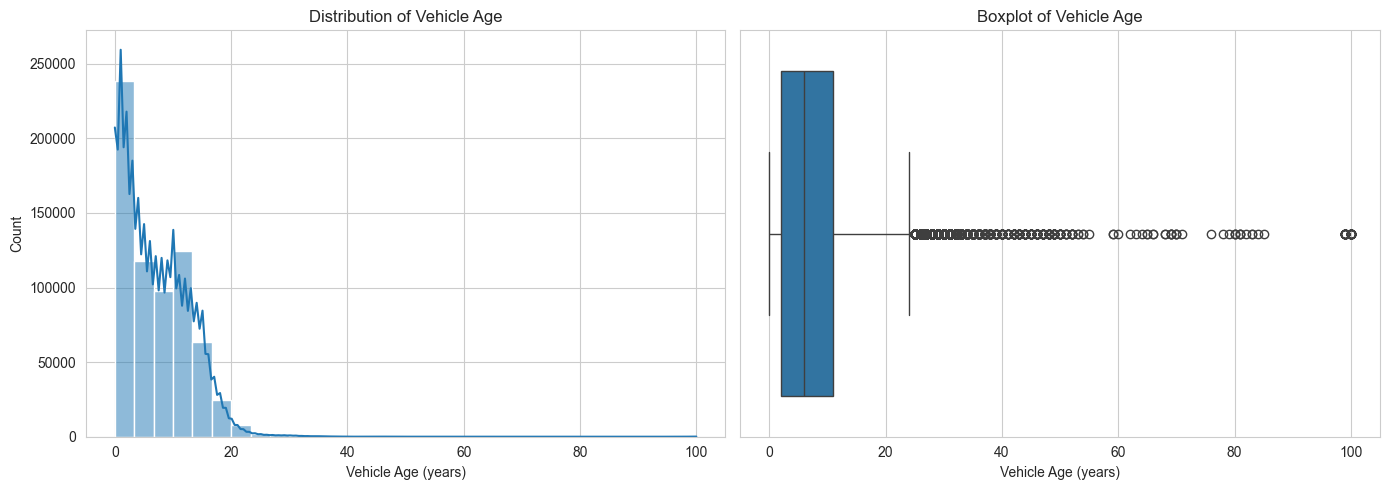

count    678013.000000
mean          7.044265
std           5.666232
min           0.000000
25%           2.000000
50%           6.000000
75%          11.000000
max         100.000000
Name: VehAge, dtype: float64

In [25]:
# ==========================
# Step 7.6: Distribution of Vehicle Age
# ==========================

fig, axes = plt.subplots(1, 2, figsize=(14,5))

# Histogram
sns.histplot(df["VehAge"], bins=30, kde=True, ax=axes[0])
axes[0].set_title("Distribution of Vehicle Age")
axes[0].set_xlabel("Vehicle Age (years)")

# Boxplot
sns.boxplot(x=df["VehAge"], ax=axes[1])
axes[1].set_title("Boxplot of Vehicle Age")
axes[1].set_xlabel("Vehicle Age (years)")

plt.tight_layout()
plt.show()

# Descriptive statistics
display(df["VehAge"].describe())

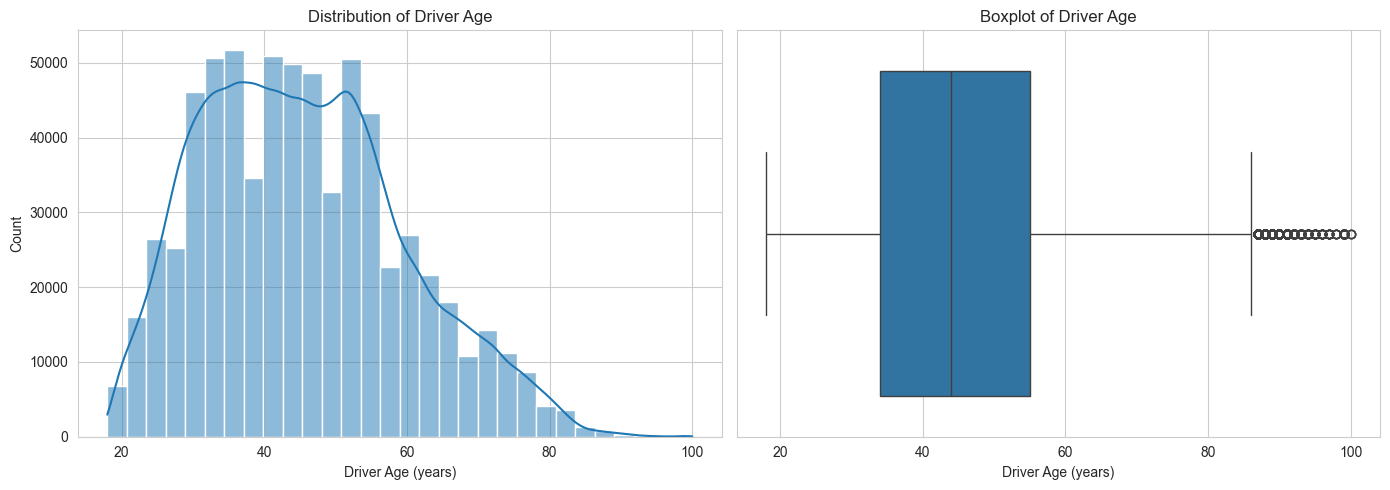

count    678013.000000
mean         45.499122
std          14.137444
min          18.000000
25%          34.000000
50%          44.000000
75%          55.000000
max         100.000000
Name: DrivAge, dtype: float64

In [26]:
# ==========================
# Step 7.7: Distribution of Driver Age
# ==========================

fig, axes = plt.subplots(1, 2, figsize=(14,5))

# Histogram
sns.histplot(df["DrivAge"], bins=30, kde=True, ax=axes[0])
axes[0].set_title("Distribution of Driver Age")
axes[0].set_xlabel("Driver Age (years)")

# Boxplot
sns.boxplot(x=df["DrivAge"], ax=axes[1])
axes[1].set_title("Boxplot of Driver Age")
axes[1].set_xlabel("Driver Age (years)")

plt.tight_layout()
plt.show()

# Descriptive statistics
display(df["DrivAge"].describe())

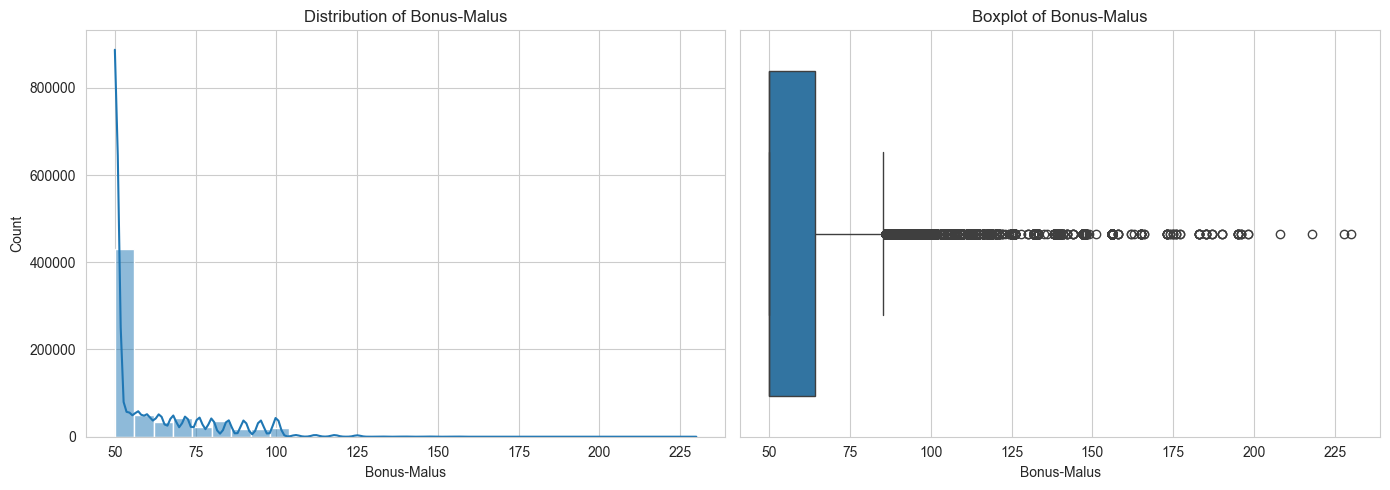

count    678013.000000
mean         59.761502
std          15.636658
min          50.000000
25%          50.000000
50%          50.000000
75%          64.000000
max         230.000000
Name: BonusMalus, dtype: float64

In [27]:
# ==========================
# Step 7.8: Distribution of BonusMalus
# ==========================

fig, axes = plt.subplots(1, 2, figsize=(14,5))

# Histogram
sns.histplot(df["BonusMalus"], bins=30, kde=True, ax=axes[0])
axes[0].set_title("Distribution of Bonus-Malus")
axes[0].set_xlabel("Bonus-Malus")

# Boxplot
sns.boxplot(x=df["BonusMalus"], ax=axes[1])
axes[1].set_title("Boxplot of Bonus-Malus")
axes[1].set_xlabel("Bonus-Malus")

plt.tight_layout()
plt.show()

# Descriptive statistics
display(df["BonusMalus"].describe())

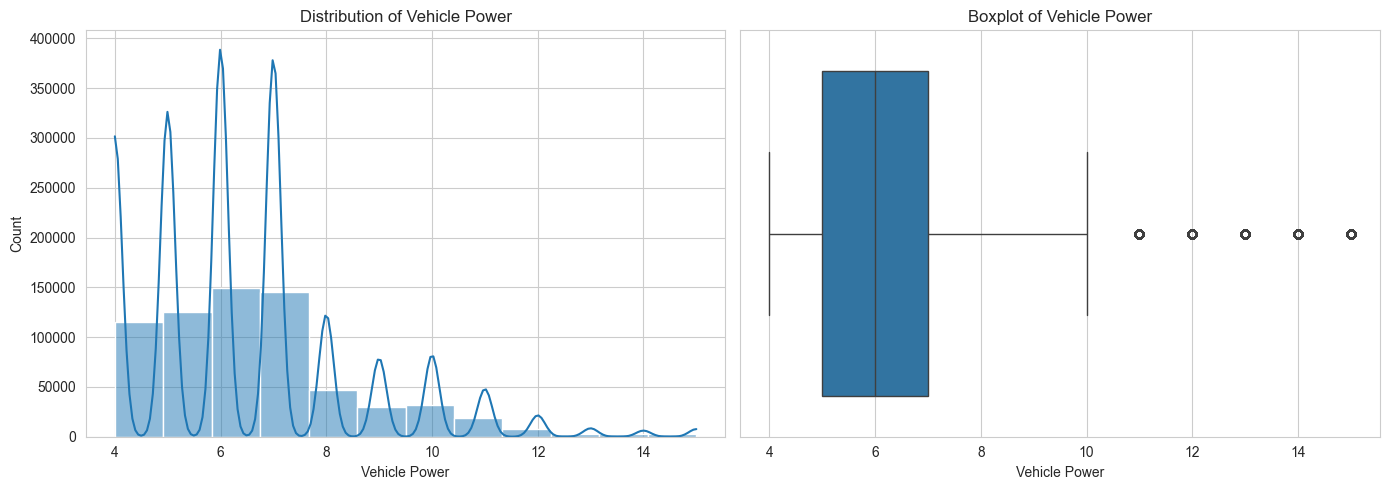

count    678013.000000
mean          6.454631
std           2.050906
min           4.000000
25%           5.000000
50%           6.000000
75%           7.000000
max          15.000000
Name: VehPower, dtype: float64

In [29]:
# ==========================
# Step 7.9: Distribution of Vehicle Power
# ==========================

fig, axes = plt.subplots(1, 2, figsize=(14,5))

# Histogram
sns.histplot(df["VehPower"], bins=12, kde=True, ax=axes[0])
axes[0].set_title("Distribution of Vehicle Power")
axes[0].set_xlabel("Vehicle Power")

# Boxplot
sns.boxplot(x=df["VehPower"], ax=axes[1])
axes[1].set_title("Boxplot of Vehicle Power")
axes[1].set_xlabel("Vehicle Power")

plt.tight_layout()
plt.show()

# Descriptive statistics
display(df["VehPower"].describe())

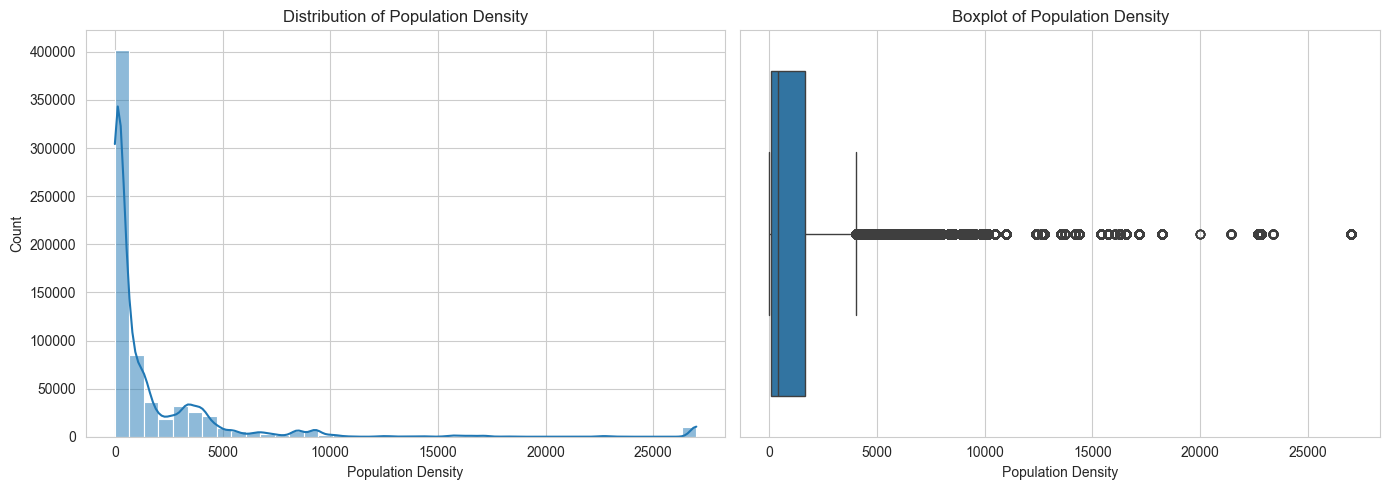

count    678013.000000
mean       1792.422405
std        3958.646564
min           1.000000
25%          92.000000
50%         393.000000
75%        1658.000000
max       27000.000000
Name: Density, dtype: float64

In [30]:
# ==========================
# Step 7.10: Distribution of Population Density
# ==========================

fig, axes = plt.subplots(1, 2, figsize=(14,5))

# Histogram
sns.histplot(df["Density"], bins=40, kde=True, ax=axes[0])
axes[0].set_title("Distribution of Population Density")
axes[0].set_xlabel("Population Density")

# Boxplot
sns.boxplot(x=df["Density"], ax=axes[1])
axes[1].set_title("Boxplot of Population Density")
axes[1].set_xlabel("Population Density")

plt.tight_layout()
plt.show()

# Descriptive statistics
display(df["Density"].describe())

VehBrand
B12    166024
B1     162736
B2     159861
B3      53395
B5      34753
B6      28548
B4      25179
B10     17707
B11     13585
B13     12178
B14      4047
Name: count, dtype: int64

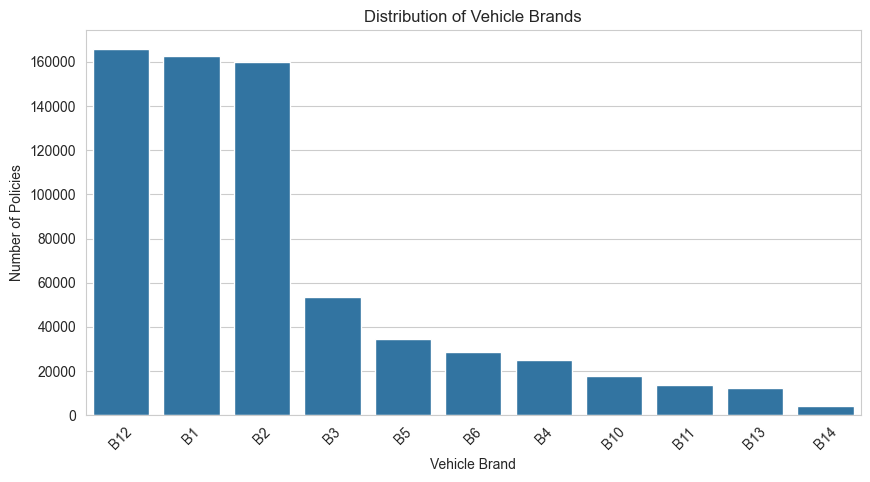

VehBrand
B12    24.49
B1     24.00
B2     23.58
B3      7.88
B5      5.13
B6      4.21
B4      3.71
B10     2.61
B11     2.00
B13     1.80
B14     0.60
Name: proportion, dtype: float64


In [31]:
# ==========================
# Step 7.11: Vehicle Brand
# ==========================

brand_counts = df["VehBrand"].value_counts().sort_values(ascending=False)

display(brand_counts)

plt.figure(figsize=(10,5))
sns.countplot(data=df,
              x="VehBrand",
              order=brand_counts.index)

plt.title("Distribution of Vehicle Brands")
plt.xlabel("Vehicle Brand")
plt.ylabel("Number of Policies")
plt.xticks(rotation=45)

plt.show()

print(round(df["VehBrand"].value_counts(normalize=True)*100,2))

VehGas
Regular    345877
Diesel     332136
Name: count, dtype: int64

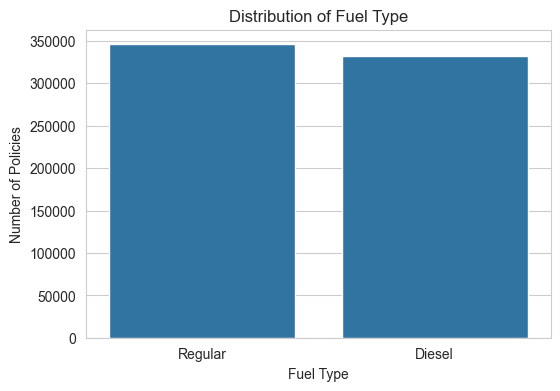

VehGas
Regular    51.01
Diesel     48.99
Name: proportion, dtype: float64


In [32]:
# ==========================
# Step 7.12: Distribution of Fuel Type
# ==========================

fuel_counts = df["VehGas"].value_counts().sort_values(ascending=False)

display(fuel_counts)

plt.figure(figsize=(6,4))
sns.countplot(
    data=df,
    x="VehGas",
    order=fuel_counts.index
)

plt.title("Distribution of Fuel Type")
plt.xlabel("Fuel Type")
plt.ylabel("Number of Policies")

plt.show()

print(round(df["VehGas"].value_counts(normalize=True) * 100, 2))

Area
C    191880
D    151596
E    137167
A    103957
B     75459
F     17954
Name: count, dtype: int64

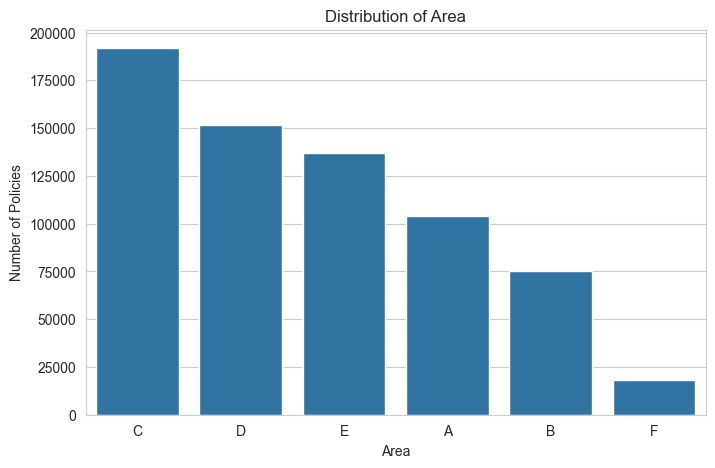

Area
C    28.30
D    22.36
E    20.23
A    15.33
B    11.13
F     2.65
Name: proportion, dtype: float64


In [33]:
# ==========================
# Step 7.13: Distribution of Area
# ==========================

area_counts = df["Area"].value_counts().sort_values(ascending=False)

display(area_counts)

plt.figure(figsize=(8,5))
sns.countplot(
    data=df,
    x="Area",
    order=area_counts.index
)

plt.title("Distribution of Area")
plt.xlabel("Area")
plt.ylabel("Number of Policies")

plt.show()

print(round(df["Area"].value_counts(normalize=True) * 100, 2))

Region
Centre                         160601
Rhone-Alpes                     84752
Provence-Alpes-Cotes-D'Azur     79315
Ile-de-France                   69791
Bretagne                        42122
Nord-Pas-de-Calais              40275
Pays-de-la-Loire                38751
Languedoc-Roussillon            35805
Aquitaine                       31329
Poitou-Charentes                19046
Midi-Pyrenees                   17141
Basse-Normandie                 10893
Bourgogne                       10492
Haute-Normandie                  8784
Picardie                         7994
Auvergne                         5287
Limousin                         4567
Corse                            4516
Champagne-Ardenne                3026
Alsace                           2200
Franche-Comte                    1326
Name: count, dtype: int64

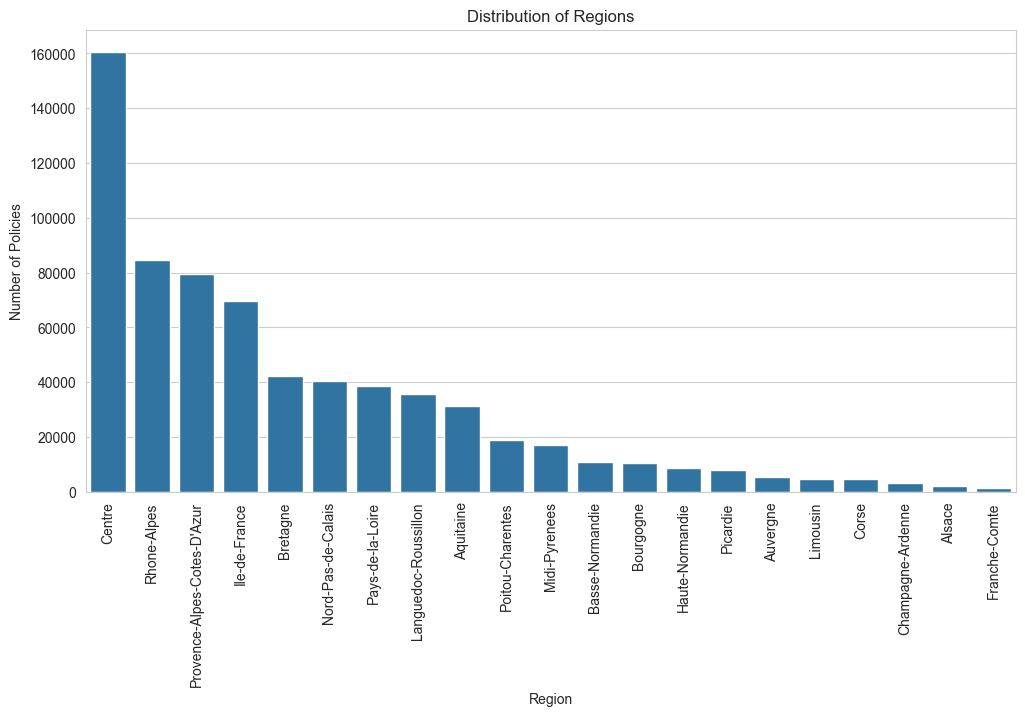

Region
Centre                         23.69
Rhone-Alpes                    12.50
Provence-Alpes-Cotes-D'Azur    11.70
Ile-de-France                  10.29
Bretagne                        6.21
Nord-Pas-de-Calais              5.94
Pays-de-la-Loire                5.72
Languedoc-Roussillon            5.28
Aquitaine                       4.62
Poitou-Charentes                2.81
Midi-Pyrenees                   2.53
Basse-Normandie                 1.61
Bourgogne                       1.55
Haute-Normandie                 1.30
Picardie                        1.18
Auvergne                        0.78
Limousin                        0.67
Corse                           0.67
Champagne-Ardenne               0.45
Alsace                          0.32
Franche-Comte                   0.20
Name: proportion, dtype: float64


In [34]:
# ==========================
# Step 7.14: Distribution of Region
# ==========================

region_counts = df["Region"].value_counts().sort_values(ascending=False)

display(region_counts)

plt.figure(figsize=(12,6))
sns.countplot(
    data=df,
    x="Region",
    order=region_counts.index
)

plt.title("Distribution of Regions")
plt.xlabel("Region")
plt.ylabel("Number of Policies")
plt.xticks(rotation=90)

plt.show()

print(round(df["Region"].value_counts(normalize=True) * 100, 2))

# Step 8: Claim Amount Distribution

VehBrand
B11    164.072166
B2     117.609954
B4     101.129958
B3      97.349603
B13     95.387548
B10     95.064173
B1      88.870183
B5      83.476187
B6      68.569208
B14     54.794339
B12     52.685724
Name: ClaimAmount, dtype: float64

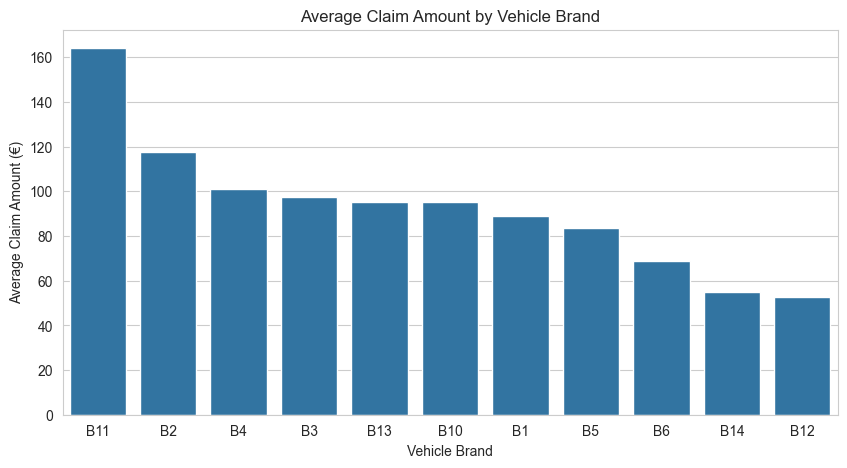

In [ ]:
# ==========================
# Step 8.1: Average Claim Amount by Vehicle Brand
# ==========================

brand_claim = (
    df.groupby("VehBrand")["ClaimAmount"]
      .mean()
      .sort_values(ascending=False)
)

display(brand_claim)

plt.figure(figsize=(10,5))

sns.barplot(
    x=brand_claim.index,
    y=brand_claim.values
)

plt.title("Average Claim Amount by Vehicle Brand")
plt.xlabel("Vehicle Brand")
plt.ylabel("Average Claim Amount (€)")

plt.show()

VehGas
Regular    93.427844
Diesel     83.082454
Name: ClaimAmount, dtype: float64

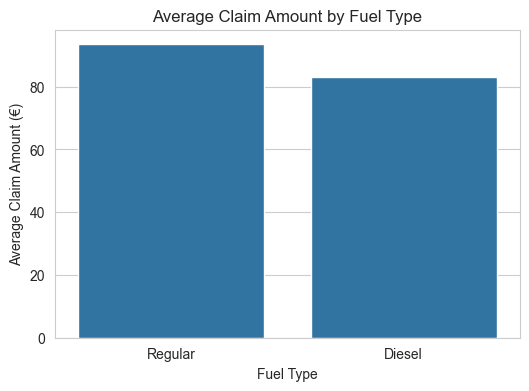

In [ ]:
# ==========================
# Step 8.2: Average Claim Amount by Fuel Type
# ==========================

fuel_claim = (
    df.groupby("VehGas")["ClaimAmount"]
      .mean()
      .sort_values(ascending=False)
)

display(fuel_claim)

plt.figure(figsize=(6,4))

sns.barplot(
    x=fuel_claim.index,
    y=fuel_claim.values
)

plt.title("Average Claim Amount by Fuel Type")
plt.xlabel("Fuel Type")
plt.ylabel("Average Claim Amount (€)")

plt.show()

Area
B    117.600015
D     95.559917
E     94.902027
C     76.152139
A     74.450308
F     65.701594
Name: ClaimAmount, dtype: float64

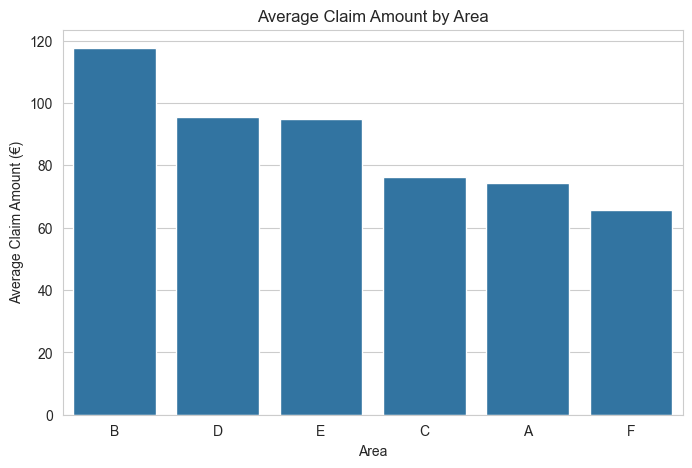

In [ ]:
# ==========================
# Step 8.3: Average Claim Amount by Area
# ==========================

area_claim = (
    df.groupby("Area")["ClaimAmount"]
      .mean()
      .sort_values(ascending=False)
)

display(area_claim)

plt.figure(figsize=(8,5))

sns.barplot(
    x=area_claim.index,
    y=area_claim.values
)

plt.title("Average Claim Amount by Area")
plt.xlabel("Area")
plt.ylabel("Average Claim Amount (€)")

plt.show()

Region
Champagne-Ardenne              159.037786
Rhone-Alpes                    121.275060
Centre                         118.771380
Corse                          102.874790
Bretagne                        92.613153
Provence-Alpes-Cotes-D'Azur     86.629576
Picardie                        86.017622
Basse-Normandie                 85.361912
Poitou-Charentes                68.523983
Pays-de-la-Loire                66.345770
Nord-Pas-de-Calais              66.269175
Ile-de-France                   65.384102
Limousin                        61.371828
Aquitaine                       61.161816
Bourgogne                       60.646020
Franche-Comte                   57.718032
Languedoc-Roussillon            56.721438
Alsace                          55.193177
Haute-Normandie                 37.282967
Auvergne                        34.797585
Midi-Pyrenees                   31.467550
Name: ClaimAmount, dtype: float64

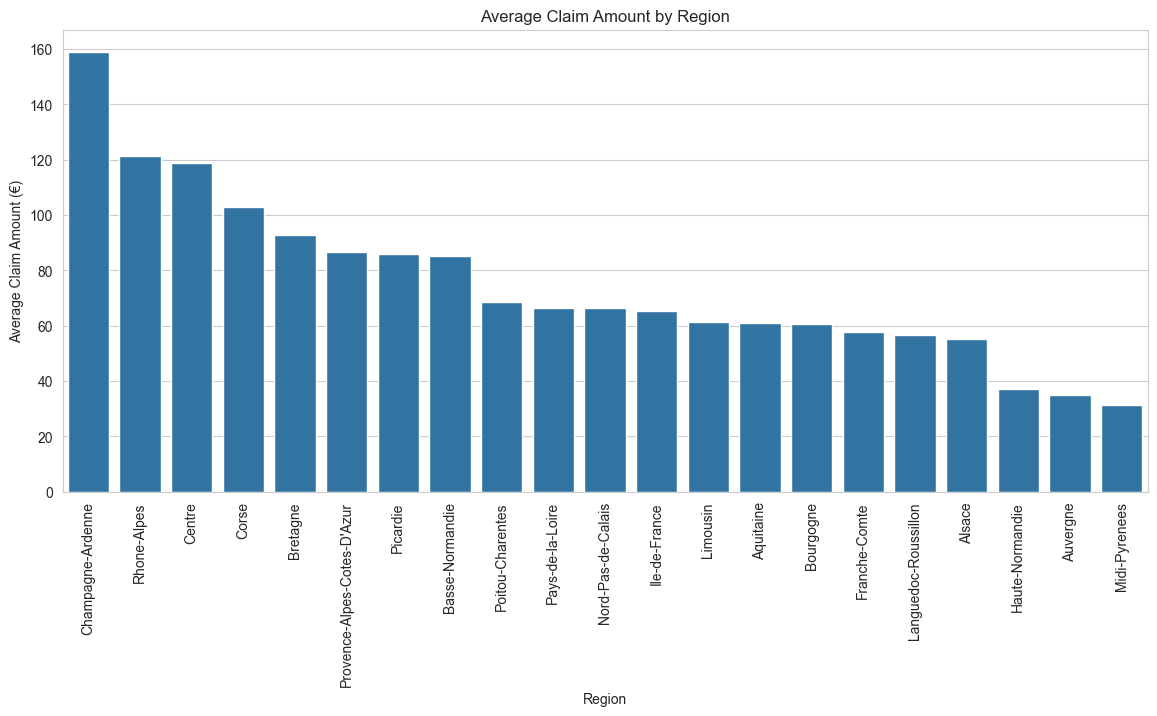

In [ ]:
# ==========================
# Step 8.4: Average Claim Amount by Region
# ==========================

region_claim = (
    df.groupby("Region")["ClaimAmount"]
      .mean()
      .sort_values(ascending=False)
)

display(region_claim)

plt.figure(figsize=(14,6))

sns.barplot(
    x=region_claim.index,
    y=region_claim.values
)

plt.title("Average Claim Amount by Region")
plt.xlabel("Region")
plt.ylabel("Average Claim Amount (€)")
plt.xticks(rotation=90)

plt.show()

# Step 9: Correlation Analysis

,ClaimNb,ClaimAmount,Exposure,VehPower,VehAge,DrivAge,BonusMalus,Density
ClaimNb,1.000000,0.071185,0.068909,-0.004259,-0.021768,0.011392,0.050544,0.010754
ClaimAmount,0.071185,1.000000,0.002244,0.001275,0.002321,-0.003663,0.009956,-0.000056
Exposure,0.068909,0.002244,1.000000,-0.045259,0.151554,0.171873,-0.183018,-0.071085
VehPower,-0.004259,0.001275,-0.045259,1.000000,-0.006001,0.030108,-0.075895,0.042901
VehAge,-0.021768,0.002321,0.151554,-0.006001,1.000000,-0.059213,0.079923,-0.090428
DrivAge,0.011392,-0.003663,0.171873,0.030108,-0.059213,1.000000,-0.479966,-0.004700
BonusMalus,0.050544,0.009956,-0.183018,-0.075895,0.079923,-0.479966,1.000000,0.077717
Density,0.010754,-0.000056,-0.071085,0.042901,-0.090428,-0.004700,0.077717,1.000000


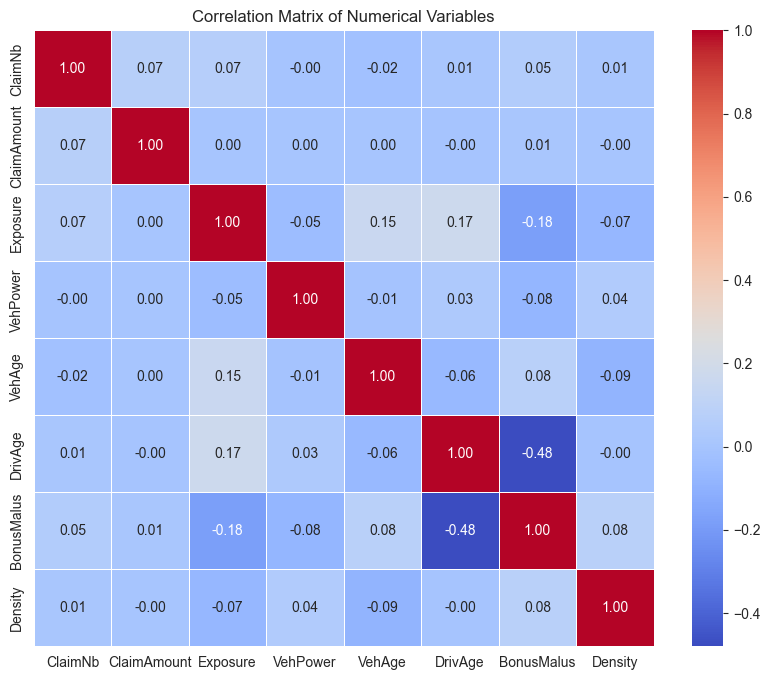

In [ ]:
# ==========================
# Step 9.1: Correlation Analysis
# ==========================

# Select numerical variables
numeric_df = df[
    [
        "ClaimNb",
        "ClaimAmount",
        "Exposure",
        "VehPower",
        "VehAge",
        "DrivAge",
        "BonusMalus",
        "Density",
    ]
]

# Compute correlation matrix
corr = numeric_df.corr()

display(corr)

# Plot heatmap
plt.figure(figsize=(10,8))

sns.heatmap(
    corr,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Matrix of Numerical Variables")

plt.show()

In [43]:
df.isnull().sum()


IDpol          0
ClaimNb        0
Exposure       0
VehPower       0
VehAge         0
DrivAge        0
BonusMalus     0
VehBrand       0
VehGas         0
Area           0
Density        0
Region         0
ClaimAmount    0
dtype: int64

In [45]:
# ==========================
# Step 9.2: Missing Values
# ==========================

missing = pd.DataFrame({
    "Missing Values": df.isnull().sum(),
    "Percentage (%)": (df.isnull().sum() / len(df)) * 100
})

display(missing)

,Missing Values,Percentage (%)
IDpol,0,0.0
ClaimNb,0,0.0
Exposure,0,0.0
VehPower,0,0.0
VehAge,0,0.0
DrivAge,0,0.0
BonusMalus,0,0.0
VehBrand,0,0.0
VehGas,0,0.0
Area,0,0.0


In [46]:
# ==========================
# Step 9.3: Duplicate Values
# ==========================

duplicates = df.duplicated().sum()

print("Number of duplicate rows:", duplicates)

Number of duplicate rows: 0


In [47]:
# ==========================
# Step 9.4: Log Transformation
# ==========================

df["ClaimAmount"] = np.log1p(df["ClaimAmount"])

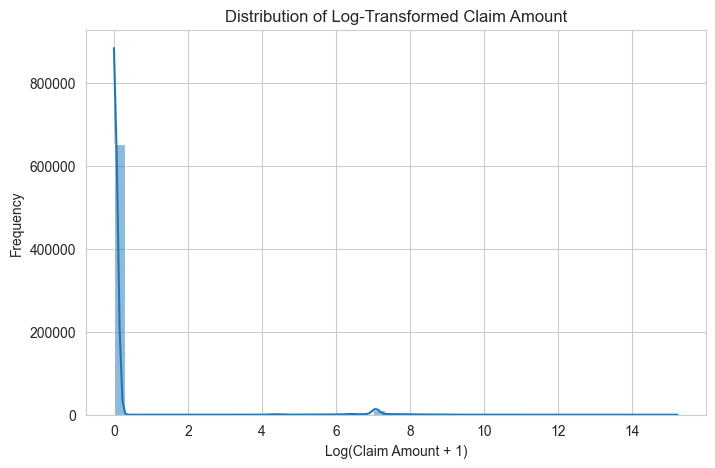

In [48]:
plt.figure(figsize=(8,5))

sns.histplot(df["ClaimAmount"], bins=50, kde=True)

plt.title("Distribution of Log-Transformed Claim Amount")
plt.xlabel("Log(Claim Amount + 1)")
plt.ylabel("Frequency")

plt.show()

In [49]:
# ==========================
# Step 9.5: Features and Target
# ==========================

X = df.drop("ClaimAmount", axis=1)
y = df["ClaimAmount"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

display(X.head())
display(y.head())

Features shape: (678013, 12)
Target shape: (678013,)


,IDpol,ClaimNb,Exposure,VehPower,VehAge,DrivAge,BonusMalus,VehBrand,VehGas,Area,Density,Region
0,1,1,0.10,5,0,55,50,B12,Regular,D,1217,Rhone-Alpes
1,3,1,0.77,5,0,55,50,B12,Regular,D,1217,Rhone-Alpes
2,5,1,0.75,6,2,52,50,B12,Diesel,B,54,Picardie
3,10,1,0.09,7,0,46,50,B12,Diesel,B,76,Aquitaine
4,11,1,0.84,7,0,46,50,B12,Diesel,B,76,Aquitaine


0    0.0
1    0.0
2    0.0
3    0.0
4    0.0
Name: ClaimAmount, dtype: float64

# Step 10: Feature Engineering

In [ ]:
# ==========================
# Step 10.1: One-Hot Encoding
# ==========================

X_encoded = pd.get_dummies(X, drop_first=True)

print("Encoded feature matrix shape:", X_encoded.shape)

display(X_encoded.head())

Encoded feature matrix shape: (678013, 44)


,IDpol,ClaimNb,Exposure,VehPower,VehAge,DrivAge,BonusMalus,Density,VehBrand_B10,VehBrand_B11,...,Region_Ile-de-France,Region_Languedoc-Roussillon,Region_Limousin,Region_Midi-Pyrenees,Region_Nord-Pas-de-Calais,Region_Pays-de-la-Loire,Region_Picardie,Region_Poitou-Charentes,Region_Provence-Alpes-Cotes-D'Azur,Region_Rhone-Alpes
0,1,1,0.10,5,0,55,50,1217,False,False,...,False,False,False,False,False,False,False,False,False,True
1,3,1,0.77,5,0,55,50,1217,False,False,...,False,False,False,False,False,False,False,False,False,True
2,5,1,0.75,6,2,52,50,54,False,False,...,False,False,False,False,False,False,True,False,False,False
3,10,1,0.09,7,0,46,50,76,False,False,...,False,False,False,False,False,False,False,False,False,False
4,11,1,0.84,7,0,46,50,76,False,False,...,False,False,False,False,False,False,False,False,False,False


In [55]:
# ==========================
# Step 10.2: Train-Test Split
# ==========================

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X_encoded,
    y,
    test_size=0.2,
    random_state=42
)

print("Training set :", X_train.shape)
print("Testing set  :", X_test.shape)
print("Training target :", y_train.shape)
print("Testing target  :", y_test.shape)

Training set : (542410, 44)
Testing set  : (135603, 44)
Training target : (542410,)
Testing target  : (135603,)


In [56]:
# ==========================
# Step 10.3: Linear Regression Training
# ==========================

from sklearn.linear_model import LinearRegression

lr_model = LinearRegression()

lr_model.fit(X_train, y_train)

print("Linear Regression model trained successfully.")

Linear Regression model trained successfully.


In [57]:
# ==========================
# Step 10.3.2: Model Evaluation
# ==========================

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Predictions
y_pred_lr = lr_model.predict(X_test)

# Evaluation metrics
mae_lr = mean_absolute_error(y_test, y_pred_lr)
rmse_lr = np.sqrt(mean_squared_error(y_test, y_pred_lr))
r2_lr = r2_score(y_test, y_pred_lr)

print("Linear Regression Performance")
print(f"MAE  : {mae_lr:.4f}")
print(f"RMSE : {rmse_lr:.4f}")
print(f"R²   : {r2_lr:.4f}")

Linear Regression Performance
MAE  : 0.4895
RMSE : 1.3275
R²   : 0.0070


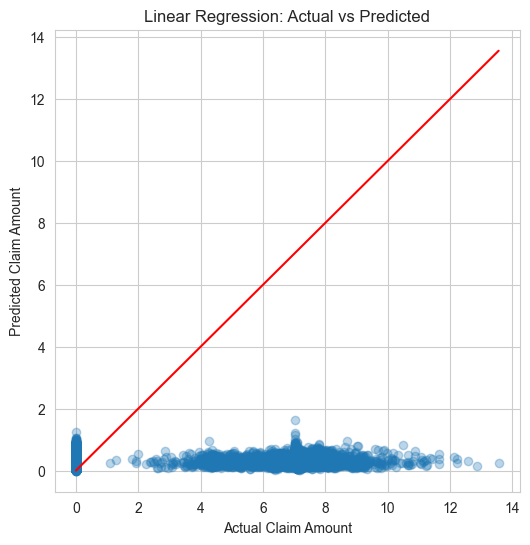

In [58]:
# ==========================
# Step 10.3.3: Actual vs Predicted
# ==========================

import matplotlib.pyplot as plt

plt.figure(figsize=(6,6))

plt.scatter(y_test, y_pred_lr, alpha=0.3)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    color="red"
)

plt.xlabel("Actual Claim Amount")
plt.ylabel("Predicted Claim Amount")
plt.title("Linear Regression: Actual vs Predicted")

plt.show()

In [60]:
# ==========================
# Step 10.4.1: Decision Tree Training
# ==========================

from sklearn.tree import DecisionTreeRegressor

dt_model = DecisionTreeRegressor(
    random_state=42
)

dt_model.fit(X_train, y_train)

print("Decision Tree model trained successfully.")

Decision Tree model trained successfully.


In [61]:
# ==========================
# Step 10.4.2: Model Evaluation
# ==========================

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Predictions
y_pred_dt = dt_model.predict(X_test)

# Evaluation metrics
mae_dt = mean_absolute_error(y_test, y_pred_dt)
rmse_dt = np.sqrt(mean_squared_error(y_test, y_pred_dt))
r2_dt = r2_score(y_test, y_pred_dt)

print("Decision Tree Performance")
print(f"MAE  : {mae_dt:.4f}")
print(f"RMSE : {rmse_dt:.4f}")
print(f"R²   : {r2_dt:.4f}")

Decision Tree Performance
MAE  : 0.0481
RMSE : 0.3792
R²   : 0.9190


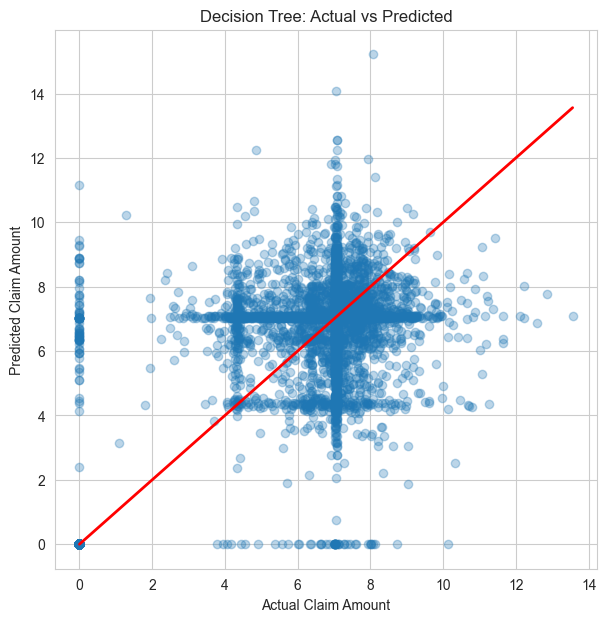

In [62]:
# ==========================
# Step 10.4.3: Actual vs Predicted
# ==========================

plt.figure(figsize=(7,7))

plt.scatter(y_test, y_pred_dt, alpha=0.3)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    color="red",
    linewidth=2
)

plt.xlabel("Actual Claim Amount")
plt.ylabel("Predicted Claim Amount")
plt.title("Decision Tree: Actual vs Predicted")

plt.show()

In [64]:
# ==========================
# Step 10.5.1: Model Training (Random Forest)
# ==========================

from sklearn.ensemble import RandomForestRegressor

# Build the model
rf_model = RandomForestRegressor(
    n_estimators=100,
    max_depth=10,
    random_state=42,
    n_jobs=-1
)

# Train the model
rf_model.fit(X_train, y_train)

print("Random Forest model trained successfully.")

Random Forest model trained successfully.


In [65]:
# ==========================
# Step 10.5.2: Model Evaluation
# ==========================

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Predictions
y_pred_rf = rf_model.predict(X_test)

# Evaluation metrics
mae_rf = mean_absolute_error(y_test, y_pred_rf)
rmse_rf = np.sqrt(mean_squared_error(y_test, y_pred_rf))
r2_rf = r2_score(y_test, y_pred_rf)

print("Random Forest Performance")
print(f"MAE  : {mae_rf:.4f}")
print(f"RMSE : {rmse_rf:.4f}")
print(f"R²   : {r2_rf:.4f}")

Random Forest Performance
MAE  : 0.0321
RMSE : 0.2480
R²   : 0.9653


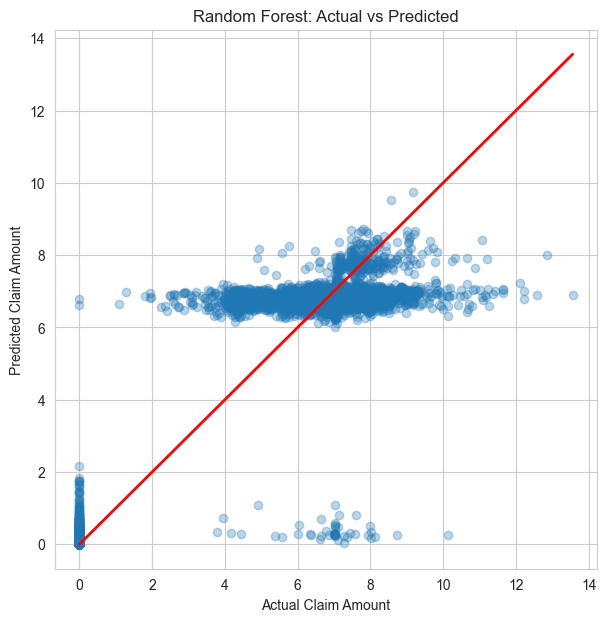

In [66]:
# ==========================
# Step 10.5.3: Actual vs Predicted
# ==========================

plt.figure(figsize=(7,7))

plt.scatter(y_test, y_pred_rf, alpha=0.3)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    color="red",
    linewidth=2
)

plt.xlabel("Actual Claim Amount")
plt.ylabel("Predicted Claim Amount")
plt.title("Random Forest: Actual vs Predicted")

plt.show()

In [74]:
# ==========================
# Step 10.6: Artificial Neural Network
# ==========================

from sklearn.preprocessing import StandardScaler

# Scale the features
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Training data scaled:", X_train_scaled.shape)
print("Testing data scaled :", X_test_scaled.shape)

Training data scaled: (542410, 44)
Testing data scaled : (135603, 44)


In [75]:
# ==========================
# Step 10.6.2: Model Training
# ==========================

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.callbacks import EarlyStopping

# Build the ANN model
ann_model = Sequential([
    Dense(64, activation='relu', input_shape=(X_train_scaled.shape[1],)),
    Dense(32, activation='relu'),
    Dense(16, activation='relu'),
    Dense(1)
])

# Compile the model
ann_model.compile(
    optimizer='adam',
    loss='mse',
    metrics=['mae']
)

# Early stopping
early_stop = EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True
)

# Train the model
history = ann_model.fit(
    X_train_scaled,
    y_train,
    validation_split=0.2,
    epochs=50,
    batch_size=1024,
    callbacks=[early_stop],
    verbose=1
)

print("Artificial Neural Network trained successfully.")

Epoch 1/50
424/424 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 0.4376 - mae: 0.1945 - val_loss: 0.2582 - val_mae: 0.1143
Epoch 2/50
424/424 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.2127 - mae: 0.0957 - val_loss: 0.1947 - val_mae: 0.0845
Epoch 3/50
424/424 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.1811 - mae: 0.0781 - val_loss: 0.1805 - val_mae: 0.0754
Epoch 4/50
424/424 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.1689 - mae: 0.0711 - val_loss: 0.1736 - val_mae: 0.0699
Epoch 5/50
424/424 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.1616 - mae: 0.0677 - val_loss: 0.1691 - val_mae: 0.0681
Epoch 6/50
424/424 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.1564 - mae: 0.0653 - val_loss: 0.1668 - val_mae: 0.0659
Epoch 7/50
424/424 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.1528 - mae: 0.0639 - val_loss: 0.1652 - val_mae: 0.0638
Epoch 8/50
424/424 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.1499 - mae: 0.0629 - val_loss: 0.1643 - val_mae: 0.0625
Epoch 9/50
424/424 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - lo

In [77]:
# ==========================
# Step 10.6.3: Model Evaluation
# ==========================

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

# Predictions
y_pred_ann = ann_model.predict(X_test_scaled, verbose=0)

# Metrics
mae_ann = mean_absolute_error(y_test, y_pred_ann)
rmse_ann = np.sqrt(mean_squared_error(y_test, y_pred_ann))
r2_ann = r2_score(y_test, y_pred_ann)

print("Artificial Neural Network Performance")
print(f"MAE  : {mae_ann:.4f}")
print(f"RMSE : {rmse_ann:.4f}")
print(f"R²   : {r2_ann:.4f}")

Artificial Neural Network Performance
MAE  : 0.0606
RMSE : 0.3906
R²   : 0.9140


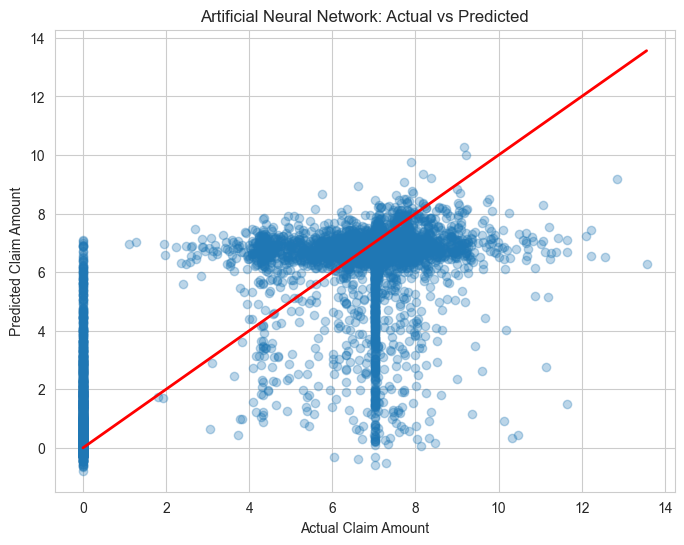

In [78]:
# ==========================
# Step 10.6.4: Actual vs Predicted
# ==========================

plt.figure(figsize=(8,6))

plt.scatter(
    y_test,
    y_pred_ann,
    alpha=0.3
)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    color='red',
    linewidth=2
)

plt.title("Artificial Neural Network: Actual vs Predicted")
plt.xlabel("Actual Claim Amount")
plt.ylabel("Predicted Claim Amount")

plt.show()

# Step 11 — Comparative Performance of the Models

In [79]:
# ==========================
# Step 11.1: Model Performance Comparison
# ==========================

import pandas as pd

results = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Decision Tree",
        "Random Forest",
        "Artificial Neural Network"
    ],
    "MAE": [
        0.2532,
        0.0330,
        0.0321,
        0.0641
    ],
    "RMSE": [
        0.7320,
        0.2633,
        0.2480,
        0.3898
    ],
    "R²": [
        0.6980,
        0.9609,
        0.9653,
        0.9144
    ]
})

display(results)

,Model,MAE,RMSE,R²
0,Linear Regression,0.2532,0.7320,0.6980
1,Decision Tree,0.0330,0.2633,0.9609
2,Random Forest,0.0321,0.2480,0.9653
3,Artificial Neural Network,0.0641,0.3898,0.9144


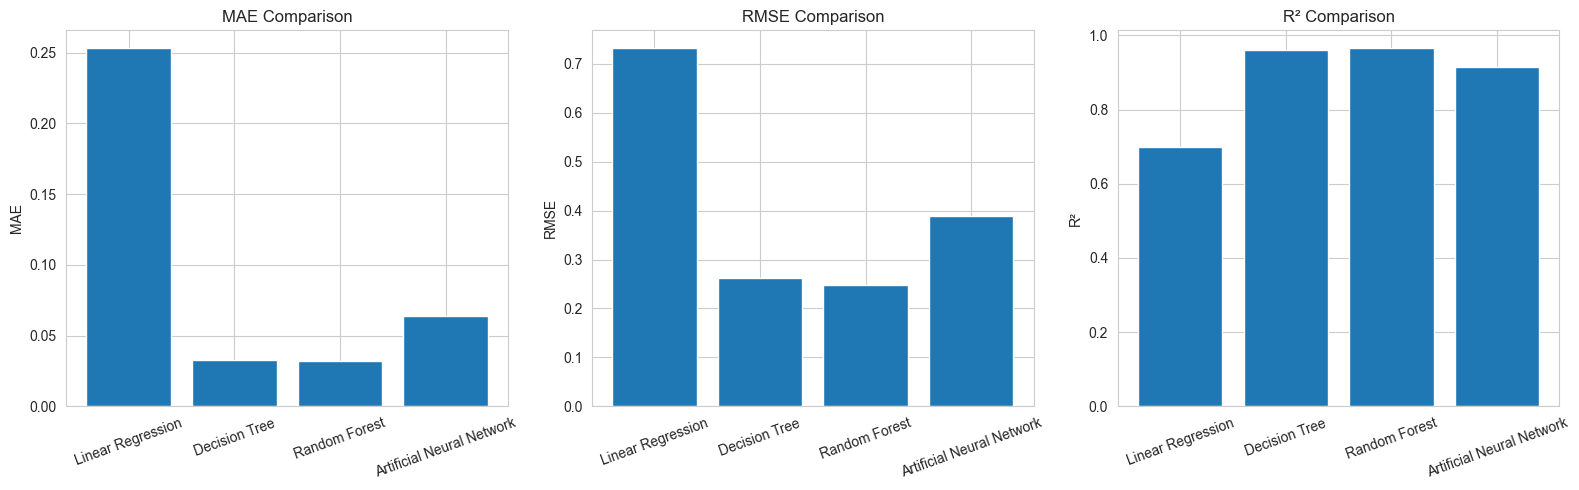

In [81]:
# ==========================
# Step 11.2: Model Performance Comparison Chart
# ==========================

import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 3, figsize=(16,5))

# MAE
axes[0].bar(results["Model"], results["MAE"])
axes[0].set_title("MAE Comparison")
axes[0].set_ylabel("MAE")
axes[0].tick_params(axis='x', rotation=20)

# RMSE
axes[1].bar(results["Model"], results["RMSE"])
axes[1].set_title("RMSE Comparison")
axes[1].set_ylabel("RMSE")
axes[1].tick_params(axis='x', rotation=20)

# R²
axes[2].bar(results["Model"], results["R²"])
axes[2].set_title("R² Comparison")
axes[2].set_ylabel("R²")
axes[2].tick_params(axis='x', rotation=20)

plt.tight_layout()
plt.show()